# Benchmark for Different Learned Image Compression Methods

### Get Benchmark Results

In [2]:
import os 
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
def get_data():
    model_names = {
        'loclic': 'LoC-LIC (Ours)',
        'mlicpp': 'MLIC++ (2024)',
        # 'LICTCM': 'LIC-TCM (2023)',
        'ELIC': 'ELIC (2022)',
        'cheng2020-anchor': 'Cheng (2020)',
        # 'bmshj2018-hyperprior': 'Balle (2018)',
        # 'mbt2018': 'Minnen (2018)',
        'bmshj2018-factorized': 'Balle (2018) - Factorized',
        'bmshj2018-hyperprior': 'Balle (2018) - Hyperprior',
        'mbt2018': 'Minnen (2018) - Hyperprior',
        'mbt2018-mean' : 'Minnen (2018) - Mean',
        # 'jpeg-ai-2025-jan-high': 'JPEG AI (2024)',
        'jpeg-ai-2025-jan-simple': 'JPEG-AI Simple (2025)',
        'jpeg-ai-2025-jan-main':   'JPEG-AI Main (2025)',
        'jpeg-ai-2025-jan-high':   'JPEG0-AI High (2025)',
        }

    datasets_names = { 'KodakDataset': 'Kodak Dataset', 'professional_valid_2020': 'CLIC Dataset'}

    main_path  = "/home/ayman/repos/summary"
    data_location = main_path 
    files_name = {
        "complexity":["result_complexity.csv", "result_time.csv", "result_syn_complexity.csv"],
        "metrics" : ["result_metrics.csv"]
                   }
    data_all =  {}
    for key, files in files_name.items():
        for single_file in files:
            key_name = key+ '_'+ single_file.split('_')[1].split('.')[0]
            data_all[key_name] = pd.read_csv(os.path.join(data_location, key, single_file)) 

    save_dir = os.path.join(main_path, 'plots') 
    os.makedirs(save_dir, exist_ok=True)
    model_names_labels = model_names.keys()
        
    return data_all, model_names, model_names_labels, save_dir, datasets_names

# Plot the results 

['loclic', 'mlicpp', 'ELIC', 'cheng2020-anchor', 'bmshj2018-factorized', 'bmshj2018-hyperprior', 'mbt2018', 'mbt2018-mean', 'jpeg-ai-2025-jan-simple', 'jpeg-ai-2025-jan-main', 'jpeg-ai-2025-jan-high']
(0.1227484809027777, 0.2084147135416666, 0.3402269151475694, 0.599151611328125, 0.7969224717881943, 1.2497355143229167) (30.10839517911275, 31.751784880956013, 33.36446793874105, 35.20249652862549, 36.88286383946737, 38.56103769938151) [0.1227484809027777, 0.599151611328125] [30.10839517911275, 35.20249652862549]
(0.1074930826822916, 0.1746554904513888, 0.2720709906684028, 0.4128790961371528, 0.5923292371961807, 0.802571614583333) (29.1623272895813, 30.716164350509644, 32.3333211739858, 34.16771038373312, 35.816238244374595, 37.32181183497111) [0.1074930826822916, 0.5923292371961807] [29.1623272895813, 35.816238244374595]
(0.0436604817708333, 0.0736355251736111, 0.1217074924045138, 0.19500732421875, 0.49713134765625, 0.864895290798611) (26.09962256749471, 27.486377954483032, 28.9515226682

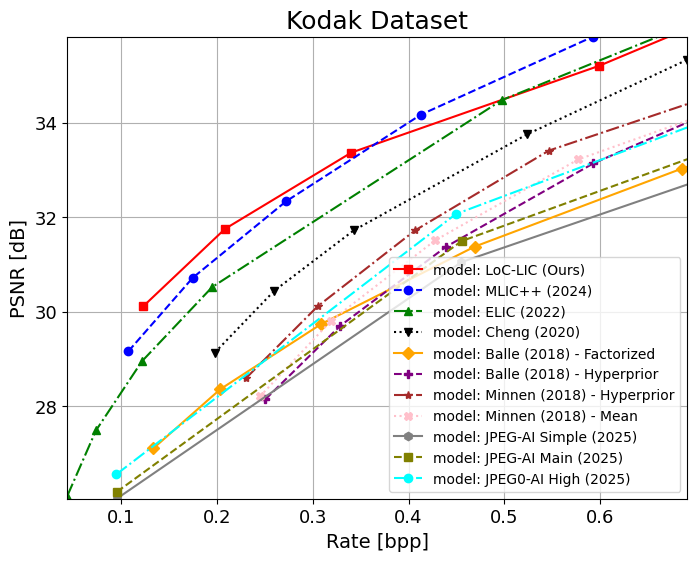

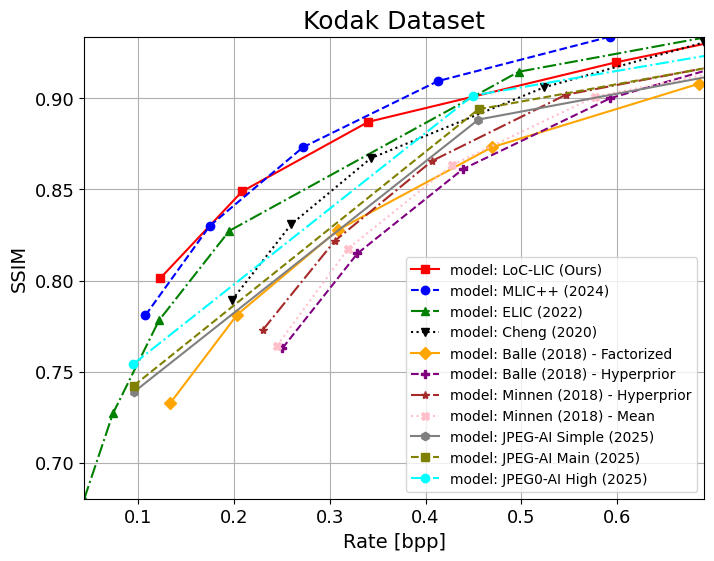

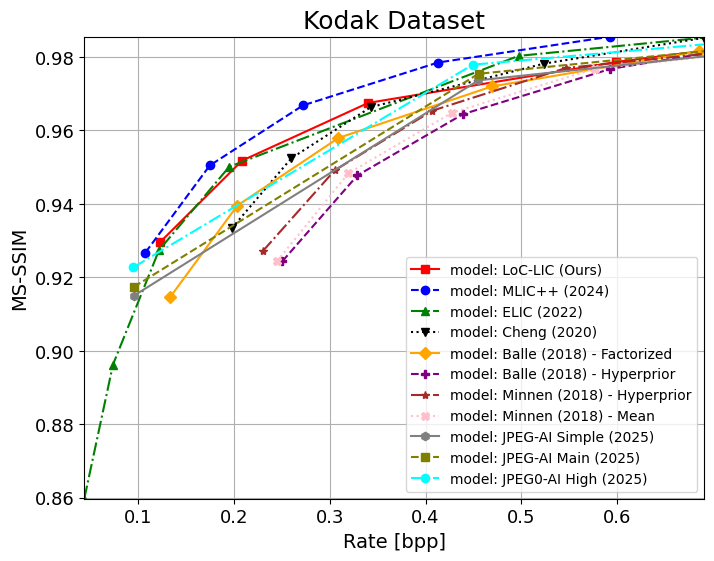

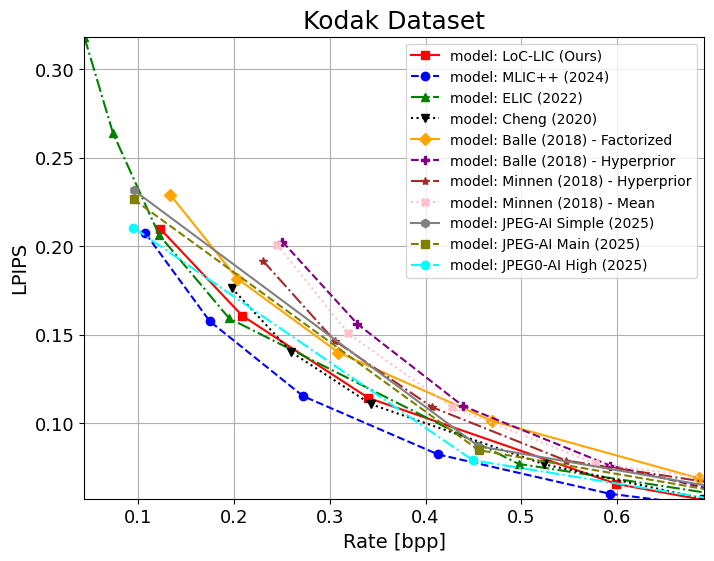

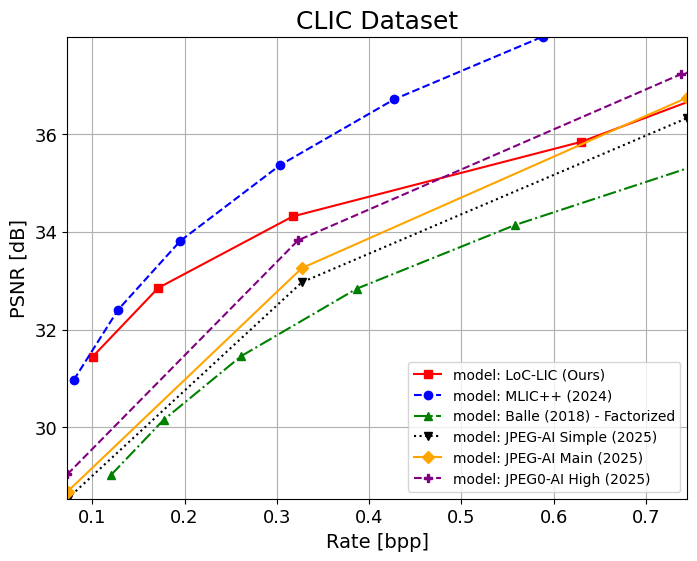

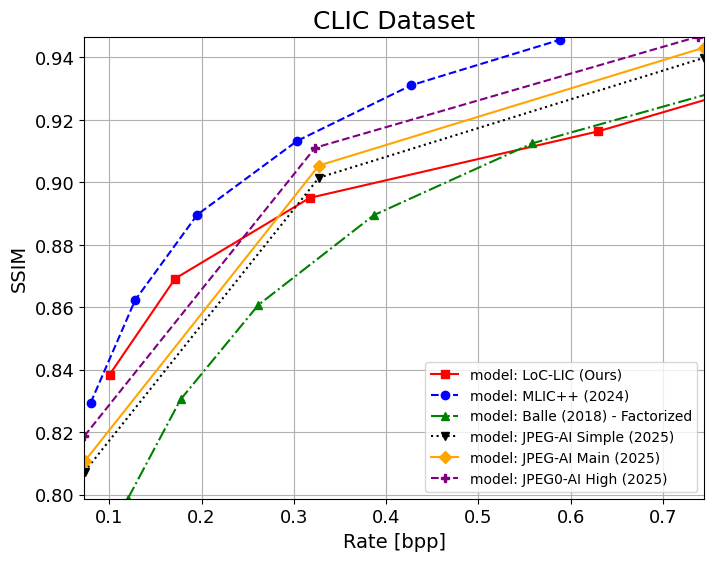

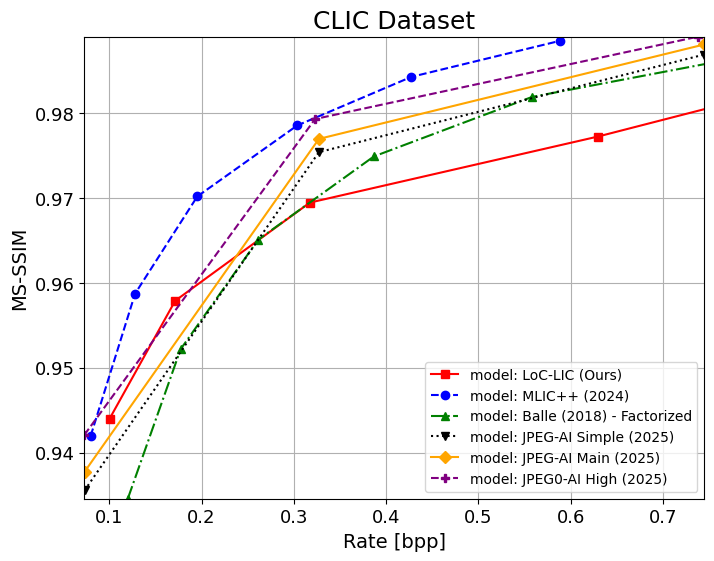

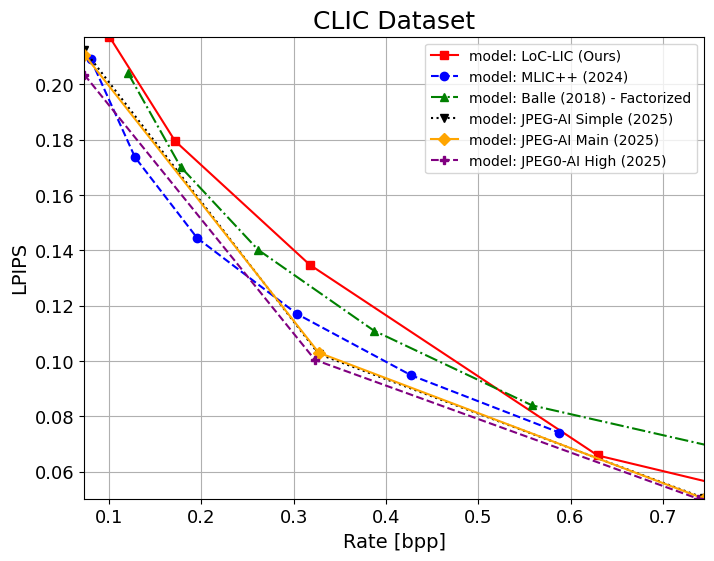

In [3]:
def prepare_data(x,y,clip_x=[0,0.75],clip_y=None):
    # sort the data based on x
    x, y = zip(*sorted(zip(x, y)))
    if clip_x is not None:
        x_new = [x[i] for i in range(len(x)) if clip_x[0] <= x[i] <= clip_x[1]]
        y_new = [y[i] for i in range(len(y)) if clip_x[0] <= x[i] <= clip_x[1]]
        limit_x = [min(x_new), max(x_new)]
        limit_y = [min(y_new), max(y_new)]
    else:
        x_new, y_new = x, y
        limit_x = [min(x), max(x)]
        limit_y = [min(y), max(y)]

    return x, y, limit_x, limit_y

def get_sorted_model_names(data, model_names_labels):
    model_names = data['model_name'].unique()
    model_names = [model_name for model_name in model_names_labels.keys() if model_name in model_names]
    return model_names

def filter_model_data(data, model_name,):
    model_data = data[data['model_name'] == model_name]
    return model_data

def plot_model_data(axes, x, y, color, label_name, line_style, marker):
    axes.plot(x, y, color=color, label=f'model: {label_name}', linestyle=line_style, marker=marker)

def set_axes_limits(axes, limit_x_all, limit_y_all):
    xlim = [min([limit[0] for limit in limit_x_all]), max([limit[1] for limit in limit_x_all])]
    ylim = [min([limit[0] for limit in limit_y_all]), max([limit[1] for limit in limit_y_all])]
    axes.set_xlim(xlim)
    axes.set_ylim(ylim)

def save_plot(fig, axes, save_dir, label_y, dataset_name, dpi=100):
    save_name = f'{label_y}_{dataset_name if dataset_name is not None else ""}'
    save_name = ''.join(e for e in save_name if e.isalnum())
    save_name = os.path.join(save_dir, save_name)
    if save_dir is not None:
        plt.savefig(f'{save_name}.png', bbox_inches='tight', dpi=dpi)
        plt.savefig(f'{save_name}.pdf', bbox_inches='tight', dpi=dpi)

def plot_data_matplotlib(data, param='psnr', label_x='Rate [bpp]', label_y='PSNR [dB]', save_dir=None, model_names_labels=None, dataset_name=None, dataset_label=None):
    texts = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)', '(i)', '(j)', '(k)', '(l)', '(m)', '(n)', '(o)', '(p)', '(q)', '(r)', '(s)', '(t)', '(u)', '(v)', '(w)', '(x)', '(y)', '(z)']
    colors = ['red', 'blue', 'green', 'black', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta', 'yellow', 'lime', 'teal', 'coral', 'lightblue', 'lightgreen', 'lightcoral', 'lightpink', 'lightgray', 'lightolive', 'lightcyan', 'lightmagenta', 'lightyellow', 'lightlime', 'lightteal', 'lightcoral']
    line_styles = ['-', '--', '-.', ':'] * 10
    markers = ['s', 'o', '^', 'v', 'D', 'P', '*', 'X', 'h'] * 10

    fig, axes = plt.subplots(figsize=(8, 6), nrows=1, ncols=1)
    limit_x_all, limit_y_all = [], []
    
    if model_names_labels is not None:
        model_names = get_sorted_model_names(data, model_names_labels)
        print(model_names)
    else:
        model_names = data['model_name'].unique()

    for j, model_name in enumerate(model_names):
        model_data = filter_model_data(data, model_name)
        label_name = model_names_labels[model_name] if model_names_labels is not None else model_name
        if model_data.empty:
            continue
        x, y, limit_x, limit_y = prepare_data(model_data['bpp'], model_data[param])
        print(x, y, limit_x, limit_y)
        limit_x_all.append(limit_x)
        limit_y_all.append(limit_y)
        plot_model_data(axes, x, y, colors[j], label_name, line_styles[j], markers[j])
    axes.grid()
    axes.set_xlabel(label_x, fontsize=14)
    axes.set_ylabel(label_y, fontsize=14)
    axes.tick_params(axis='both', which='major', labelsize=13)
    axes.legend(loc='best')
    if dataset_label is not None:
        axes.set_title(f'{dataset_label}', fontsize=18)
    set_axes_limits(axes, limit_x_all, limit_y_all)
    save_plot(fig, axes, save_dir, label_y, dataset_name)

if __name__ == '__main__':

    data_all, model_names, model_names_labels, save_dir, datasets_names_labels = get_data()
    data = data_all["metrics_metrics"]
    data = data[data['model_name'].isin(model_names_labels)]
    y_labels = ["PSNR [dB]", "SSIM", "MS-SSIM", "LPIPS",]
    metrics = ['psnr','ssim','msssim','lpips',]
    datasets_name = data['dataset_name'].unique()
    for dataset_name in datasets_name:
        data_model_dataset = data[data['dataset_name'] == dataset_name]
        dataset_label = datasets_names_labels[dataset_name]
        for k, metric in enumerate(metrics):
            plot_data_matplotlib(data_model_dataset, metric, save_dir=save_dir, model_names_labels=model_names,label_y=y_labels[k], dataset_name=dataset_name, dataset_label=dataset_label)


# Bar plot

['bmshj2018-factorized' 'bmshj2018-hyperprior' 'mbt2018-mean' 'mbt2018'
 'cheng2020-anchor' 'ELIC' 'mlicpp' 'loclic' 'jpeg-ai-2025-jan-high'
 'jpeg-ai-2025-jan-main' 'jpeg-ai-2025-jan-simple']
dict_keys(['loclic', 'mlicpp', 'ELIC', 'cheng2020-anchor', 'bmshj2018-factorized', 'bmshj2018-hyperprior', 'mbt2018', 'mbt2018-mean', 'jpeg-ai-2025-jan-simple', 'jpeg-ai-2025-jan-main', 'jpeg-ai-2025-jan-high'])


/tmp/ipykernel_1469310/3430982421.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes.legend(loc='best')


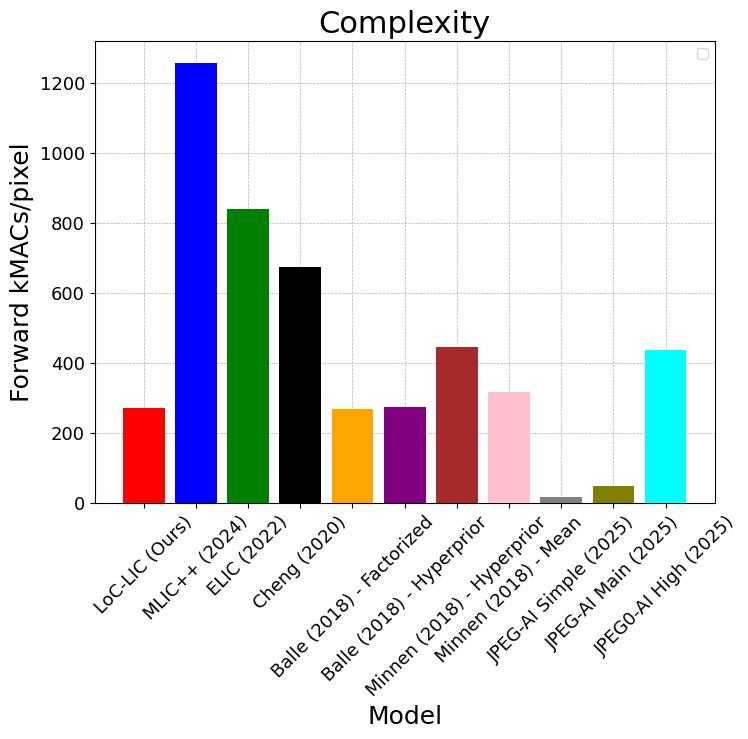

In [4]:
def bar_plot(axes, x, y, color):
    axes.bar(x, y, color=color,zorder=3)


def save_plot(fig, axes, save_dir, label_y, dataset_name, dpi=100):
    if save_dir is not None:
        plt.savefig(f'{save_dir}/{label_y}_{dataset_name if dataset_name is not None else ""}.png', bbox_inches='tight', dpi=dpi)
        plt.savefig(f'{save_dir}/{label_y}_{dataset_name if dataset_name is not None else ""}.pdf', bbox_inches='tight', dpi=dpi)

def plot_data_matplotlib(x, y, label_x='Model', label_y='PSNR [dB]', save_dir=None, dataset_name=None, save_name=None):
    colors = ['red', 'blue', 'green', 'black', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta', 'yellow', 'lime', 'teal', 'coral', 'lightblue', 'lightgreen', 'lightcoral', 'lightpink', 'lightgray', 'lightolive', 'lightcyan', 'lightmagenta', 'lightyellow', 'lightlime', 'lightteal', 'lightcoral']
    fig, axes = plt.subplots(figsize=(8, 6), nrows=1, ncols=1)

    axes.grid(True, which='both', linestyle='--', linewidth=0.5, zorder=0)
    for j, model_name in enumerate(x):
        x_single, y_single = model_name, y[j]
        bar_plot(axes, x_single, y_single, colors[j])
    axes.set_xlabel(label_x, fontsize=18)
    axes.set_ylabel(label_y, fontsize=18)
    axes.tick_params(axis='both', which='major', labelsize=13)
    for tick in axes.get_xticklabels():
        tick.set_rotation(45)
    axes.legend(loc='best')
    axes.set_title("Complexity", fontsize=22)
    save_plot(fig, axes, save_dir, save_name, dataset_name)

if __name__ == '__main__':

    data_all, model_names, model_names_labels, save_dir, _  = get_data()
 
    data = data_all["complexity_complexity"] # ['complexity_complexity', 'complexity_time', 'complexity_syn']
    print(data['model_name'].unique())
    data = data[data['model_name'].isin(model_names_labels)]
    print(model_names_labels)
    y_labels = ["kMACs/pixel"] # ["Total mult-adds [G]"]
    input_size = data[data['input_size'] == '256_256'] # get the input size of 256*256
    input_size_value = 256*256
    complexity = np.array([input_size[input_size['model_name'] == model_name]['Total mult-adds'].mean() for model_name in model_names_labels])/input_size_value # in GMACs # get the mean value of the complexity for each model
    x = [model_names[model_name] for model_name in model_names.keys()]
    y = complexity*10**6 # in kMACs
    plot_data_matplotlib(x, y, label_y='Forward kMACs/pixel', save_dir=save_dir, dataset_name='256_256',save_name='complexity')
   


# Bjontegaard metrics plot

# Time vs Image Size

Saved time results to /home/ayman/repos/summary/plots/time_vs_image_size.csv


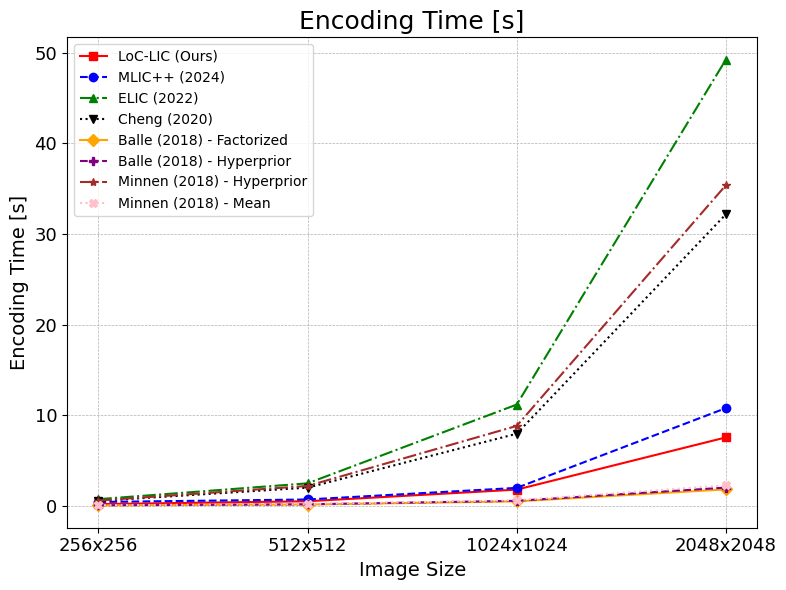

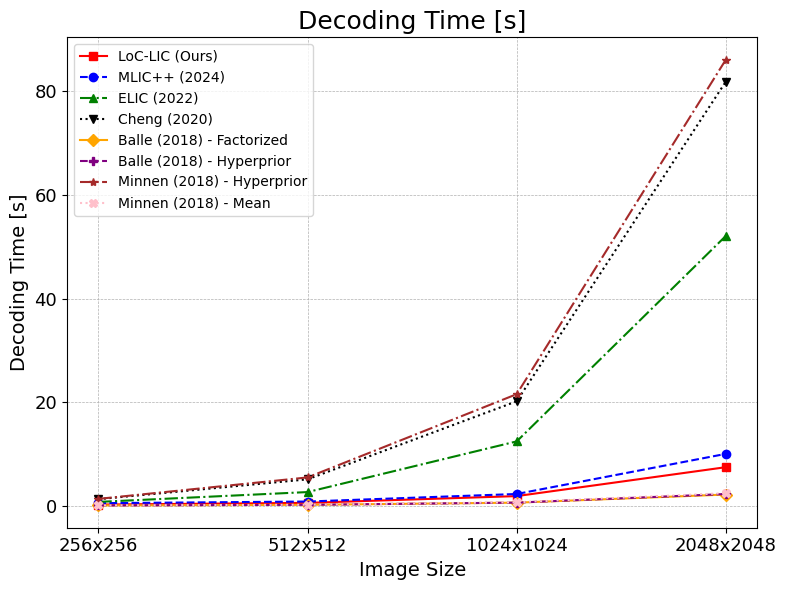

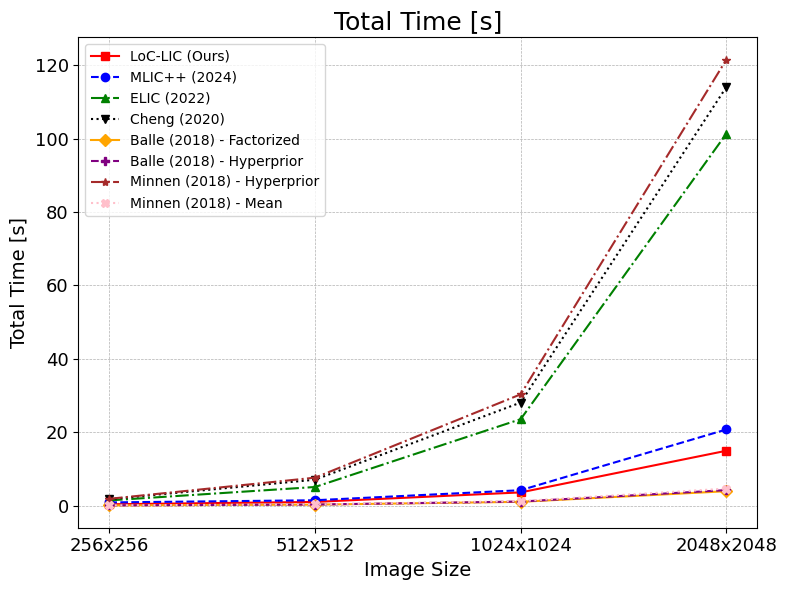

In [5]:
def plot_time_vs_size(data, time_col, label_y, model_names_labels, save_dir=None, save_name=None):
    colors = ['red', 'blue', 'green', 'black', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta']
    line_styles = ['-', '--', '-.', ':'] * 10
    markers = ['s', 'o', '^', 'v', 'D', 'P', '*', 'X', 'h'] * 10

    fig, axes = plt.subplots(figsize=(8, 6))
    sorted_models = [m for m in model_names_labels.keys() if m in data['model_name'].str.strip().unique()]

    for j, model in enumerate(sorted_models):
        model_data = data[data['model_name'].str.strip() == model]
        # average over qualities for each input size
        grouped = model_data.groupby('input_size')[time_col].mean().reset_index()
        # parse image size to total pixels
        grouped['pixels'] = grouped['input_size'].str.strip().apply(lambda s: int(s.split('_')[0]) * int(s.split('_')[1]))
        grouped = grouped.sort_values('pixels')
        size_labels = grouped['input_size'].str.strip().str.replace('_', 'x')
        axes.plot(size_labels, grouped[time_col].values, color=colors[j % len(colors)],
                  label=model_names_labels[model], linestyle=line_styles[j], marker=markers[j])

    axes.grid(True, linestyle='--', linewidth=0.5)
    axes.set_xlabel('Image Size', fontsize=14)
    axes.set_ylabel(label_y, fontsize=14)
    axes.set_title(label_y, fontsize=18)
    axes.tick_params(axis='both', which='major', labelsize=13)
    axes.legend(loc='best', fontsize=10)
    plt.tight_layout()
    if save_dir is not None and save_name is not None:
        plt.savefig(os.path.join(save_dir, f'{save_name}.png'), bbox_inches='tight', dpi=100)
        plt.savefig(os.path.join(save_dir, f'{save_name}.pdf'), bbox_inches='tight', dpi=100)
    plt.show()

data_all, model_names, model_names_labels, save_dir, _ = get_data()
data_time = data_all["complexity_time"]

# Strip whitespace from column names
data_time.columns = data_time.columns.str.strip()
data_time = data_time[data_time['model_name'].str.strip().isin(model_names_labels)]

# Save time results as CSV (averaged over qualities per model & image size)
time_avg = data_time.groupby(['model_name', 'input_size'])[['Encod time', 'Decod time', 'Total time']].mean().reset_index()
time_csv = os.path.join(save_dir, 'time_vs_image_size.csv')
time_avg.to_csv(time_csv, index=False)
print(f'Saved time results to {time_csv}')

plot_time_vs_size(data_time, 'Encod time', 'Encoding Time [s]', model_names, save_dir=save_dir, save_name='enc_time_vs_size')
plot_time_vs_size(data_time, 'Decod time', 'Decoding Time [s]', model_names, save_dir=save_dir, save_name='dec_time_vs_size')
plot_time_vs_size(data_time, 'Total time', 'Total Time [s]', model_names, save_dir=save_dir, save_name='total_time_vs_size')

/home/ayman/miniconda/envs/TokenCompression/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['KodakDataset' 'professional_valid_2020']
loclic & KodakDataset 1.39 & -29.19 & 17.75 \\
mlicpp & KodakDataset 1.56 & -30.49 & 82.35 \\
ELIC & KodakDataset 1.04 & -20.88 & 55.09 \\
cheng2020-anchor & KodakDataset 0.00 & 0.00 & 44.22 \\
bmshj2018-factorized & KodakDataset -1.72 & 46.05 & 17.57 \\
bmshj2018-hyperprior & KodakDataset -1.54 & 32.05 & 17.99 \\
mbt2018 & KodakDataset -0.87 & 17.93 & 29.16 \\
mbt2018-mean & KodakDataset -1.34 & 27.61 & 20.77 \\
jpeg-ai-2025-jan-simple & KodakDataset -2.01 & 56.51 & 1.08 \\
jpeg-ai-2025-jan-main & KodakDataset -1.62 & 38.75 & 3.11 \\
jpeg-ai-2025-jan-high & KodakDataset -0.98 & 20.57 & 28.61 \\
Saved BD metrics to /home/ayman/repos/summary/plots/bd_metrics.csv


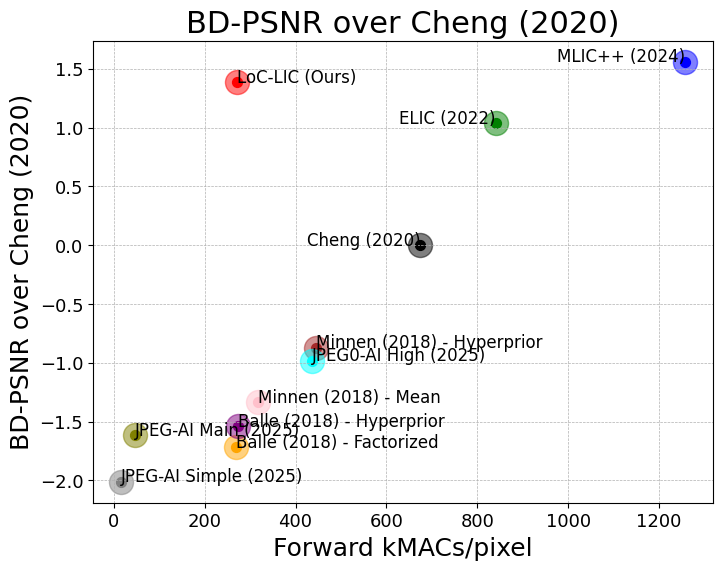

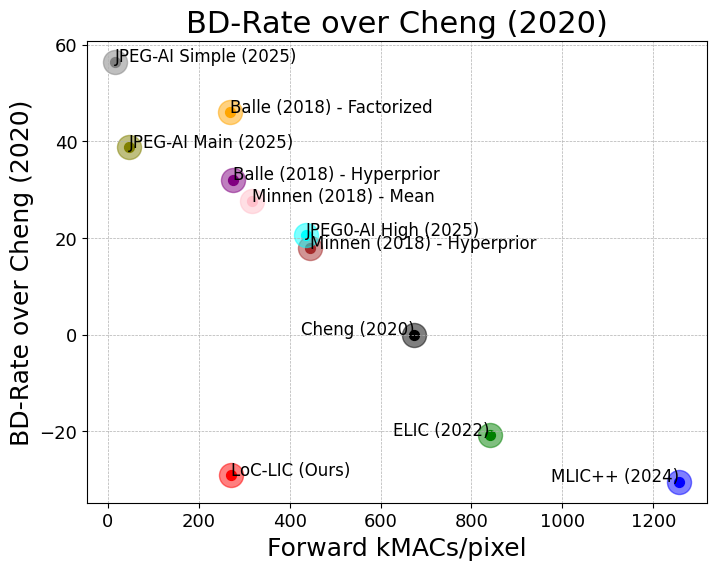

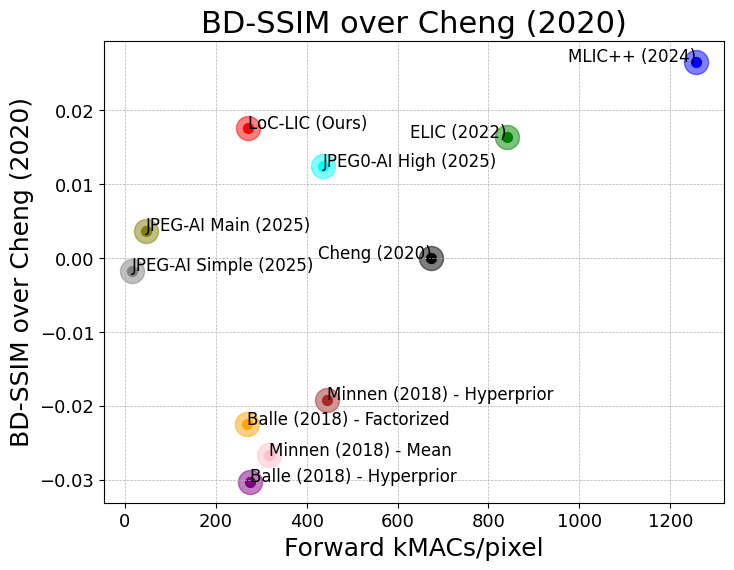

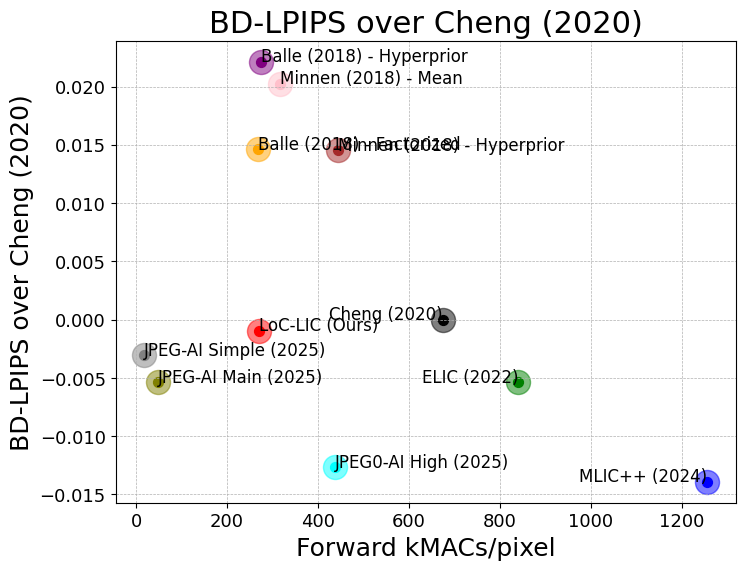

In [6]:
import sys 
repo_path = "/home/ayman/repos/loc-lic"
sys.path.append(repo_path)
from utils.metrics import bjontegaard_metric_psnr, bjontegaard_metric_rate

def save_plot(fig, axes, save_dir, label_y, dataset_name, dpi=100):
    if save_dir is not None:
        plt.savefig(f'{save_dir}/{label_y}_{dataset_name if dataset_name is not None else ""}.png', bbox_inches='tight', dpi=dpi)
        plt.savefig(f'{save_dir}/{label_y}_{dataset_name if dataset_name is not None else ""}.pdf', bbox_inches='tight', dpi=dpi)

def plot_points(x, y, model_names, label_x=None, label_y=None, save_dir=None, dataset_name=None, save_name=None):
    colors = ['red', 'blue', 'green', 'black', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta', 'yellow', 'lime', 'teal', 'coral', 'lightblue', 'lightgreen', 'lightcoral', 'lightpink', 'lightgray', 'lightolive', 'lightcyan', 'lightmagenta', 'lightyellow', 'lightlime', 'lightteal', 'lightcoral']
    fig, axes = plt.subplots(figsize=(8, 6), nrows=1, ncols=1)

    axes.grid(True, which='both', linestyle='--', linewidth=0.5, zorder=0)
    size_outer = 300
    size_inner = 50 
    center = (max(x) + min(x))/2
    for j in range(len(x)):
        model_name = model_names[j]
        x_single, y_single = x[j], y[j]
        color = colors[j]
        plt.scatter(x_single, y_single, c=color, s=size_outer, alpha=0.5, label=model_name)
        plt.scatter(x_single, y_single, c=color, s=size_inner, alpha=1)
        # plt.text(x_single, y_single, f'{model_name}', fontsize=12, color='black', ha='center', va='center')
        plt.text(x_single, y_single, f'{model_name}', fontsize=12, color='black', ha='right' if x_single > center else 'left')

    
    axes.set_xlabel(label_x, fontsize=18)
    axes.set_ylabel(label_y, fontsize=18)
    axes.tick_params(axis='both', which='major', labelsize=13)
    # axes.legend(loc='best')
    axes.set_title(label_y, fontsize=22)
    save_plot(fig, axes, save_dir, save_name, dataset_name)
    plt.show()

data_all, model_names, model_names_labels, save_dir, datasets_names_labels = get_data()

data_metrics = data_all["metrics_metrics"]
data_complexity = data_all["complexity_complexity"]
input_size = '256_256'
anchor_model = "cheng2020-anchor"
dataset_all = data_metrics['dataset_name'].unique()
print(dataset_all)
data_metrics = data_metrics[data_metrics['dataset_name'] == dataset_all[0]] # KodakDataset
anchor_psnr = data_metrics[(data_metrics['model_name'] == anchor_model)]['psnr']
anchor_bpp = data_metrics[(data_metrics['model_name'] == anchor_model)]['bpp']
anchor_ssims = data_metrics[(data_metrics['model_name'] == anchor_model)]['ssim']
anchor_lpips = data_metrics[(data_metrics['model_name'] == anchor_model)]['lpips']
save_csv = os.path.join(save_dir, 'bd_metrics.csv')

rows = []
psnr_all, bpp_all, ssim_all, lpips_all, complexity_all, model_names_all = [], [], [], [], [], []
for model in model_names_labels: 
    data_model = data_metrics[data_metrics['model_name'] == model]
    psnr = data_model['psnr']
    bpp = data_model['bpp']
    ssim = data_model['ssim']
    lpips = data_model['lpips']
    bd_psnr = bjontegaard_metric_psnr(anchor_bpp, anchor_psnr, bpp, psnr)
    bd_ssim = bjontegaard_metric_psnr(anchor_bpp, anchor_ssims, bpp, ssim)
    bd_lpips = bjontegaard_metric_psnr(anchor_bpp, anchor_lpips, bpp, lpips)
    bd_rate = bjontegaard_metric_rate(anchor_bpp, anchor_psnr, bpp, psnr)
    data_model_complexity = data_complexity[data_complexity['model_name'] == model]
    complexity = data_model_complexity[data_model_complexity['input_size'] == input_size]['Total mult-adds'].mean()
    if complexity is np.nan:
        continue
    psnr_all.append(bd_psnr)
    bpp_all.append(bd_rate)
    ssim_all.append(bd_ssim)
    lpips_all.append(bd_lpips)
    complexity_all.append(complexity/(256*256)*10**6)
    model_names_all.append(model_names[model])
    print (f'{model} & {dataset_all[0]} {bd_psnr:.2f} & {bd_rate:.2f} & {complexity:.2f} \\\\')
    rows.append({
        'model_name': model,
        'bd_psnr': bd_psnr,
        'bd_rate': bd_rate,
        'bd_ssim': bd_ssim,
        'bd_lpips': bd_lpips,
        'complexity_kmacs_per_pixel': complexity/(256*256)*10**6,
    })

df_results = pd.DataFrame(rows)
df_results.to_csv(save_csv, index=False)
print(f'Saved BD metrics to {save_csv}')

plot_points(complexity_all, psnr_all, model_names_all, label_x='Forward kMACs/pixel', label_y='BD-PSNR over Cheng (2020)', save_dir=save_dir, dataset_name=input_size, save_name='bd_psnr')
plot_points(complexity_all, bpp_all, model_names_all, label_x='Forward kMACs/pixel', label_y='BD-Rate over Cheng (2020)', save_dir=save_dir, dataset_name=input_size, save_name='bd_rate')
plot_points(complexity_all, ssim_all, model_names_all, label_x='Forward kMACs/pixel', label_y='BD-SSIM over Cheng (2020)', save_dir=save_dir, dataset_name=input_size, save_name='bd_ssim')
plot_points(complexity_all, lpips_all, model_names_all, label_x='Forward kMACs/pixel', label_y='BD-LPIPS over Cheng (2020)', save_dir=save_dir, dataset_name=input_size, save_name='bd_lpips')